# Homework 4 - Evaluacion de modelos
ML Zoomcamp 2026 - Laura

mismo dataset de leads de la tarea 3, target = `converted`

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### preparacion
igual que en la tarea 3: categoricas -> 'NA', numericas -> 0.0

In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categoricas = list(df.select_dtypes(include=['object', 'string']).columns)
numericas = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[categoricas] = df[categoricas].fillna('NA')
df[numericas] = df[numericas].fillna(0.0)

df.isnull().sum().sum()

np.int64(0)

### split
ojo: esta vez random_state=1 (en la tarea 3 era 42)

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [6]:
y_train = df_train.converted.values
y_val = df_val.converted.values

del df_train['converted']
del df_val['converted']

### Q1 - AUC de cada variable numerica
uso la variable directamente como si fuera la prediccion. si da < 0.5 la invierto con -

In [7]:
for col in numericas:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
        print(col, round(auc, 3), '(invertida)')
    else:
        print(col, round(auc, 3))

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


### Q2 - entrenar el modelo

In [8]:
columnas = categoricas + numericas

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[columnas].to_dict(orient='records'))
X_val = dv.transform(df_val[columnas].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
round(roc_auc_score(y_val, y_pred), 3)

0.732

### Q3 - precision y recall por threshold
lo hago a mano con TP/FP/FN como en la clase

In [9]:
thresholds = np.arange(0.0, 1.01, 0.01)
filas = []

for t in thresholds:
    pred_pos = y_pred >= t
    real_pos = y_val == 1

    tp = (pred_pos & real_pos).sum()
    fp = (pred_pos & ~real_pos).sum()
    fn = (~pred_pos & real_pos).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    filas.append((round(t, 2), p, r))

df_scores = pd.DataFrame(filas, columns=['threshold', 'precision', 'recall'])
df_scores.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


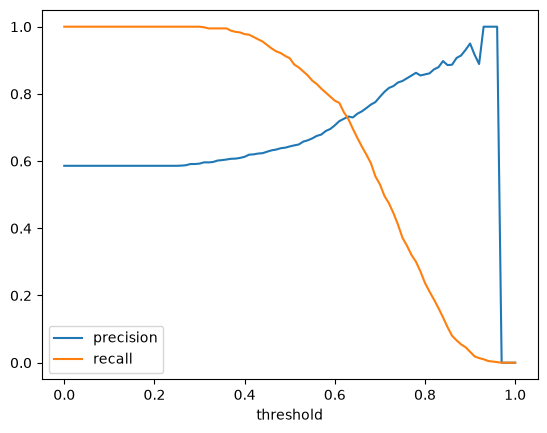

In [10]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

In [11]:
# donde se cruzan: menor diferencia, quitando donde las dos son 0
aux = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
aux['dif'] = (aux.precision - aux.recall).abs()
aux.sort_values('dif').head()

,threshold,precision,recall,dif
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


### Q4 - F1

In [12]:
df_scores['f1'] = 2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)
df_scores.sort_values('f1', ascending=False).head()

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


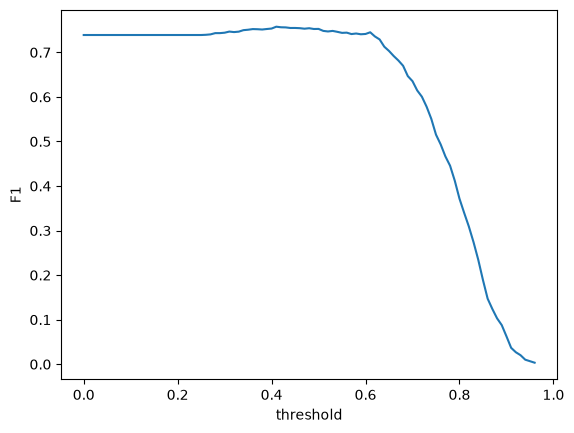

In [13]:
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold')
plt.ylabel('F1')
plt.show()

### Q5 - 5-fold cross validation
funcion para entrenar y predecir y no repetir codigo

In [14]:
def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[columnas].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[columnas].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [15]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_v = df_full_train.iloc[val_idx]

    dv, model = train(df_tr, df_tr.converted.values)
    pred = predict(df_v, dv, model)
    scores.append(roc_auc_score(df_v.converted.values, pred))

print(np.round(scores, 3))
print('media', round(np.mean(scores), 3), 'std', round(np.std(scores), 3))

[0.731 0.73  0.736 0.741 0.721]
media 0.732 std 0.007


### Q6 - buscar el mejor C con CV

In [16]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_v = df_full_train.iloc[val_idx]

        dv, model = train(df_tr, df_tr.converted.values, C=C)
        pred = predict(df_v, dv, model)
        scores.append(roc_auc_score(df_v.converted.values, pred))

    print(C, round(np.mean(scores), 3), round(np.std(scores), 3))

1e-06 0.617 0.019
0.001 0.749 0.01
1 0.732 0.007
